# Phase 7 — Ablations: the geographic shortcut and user snapshots

**Follows:** `06_ft_transformer.ipynb`. Final validation PR-AUC: CatBoost 0.864, Random Forest 0.716, FT-Transformer 0.533, logistic regression 0.152.

**Question:** how much of that performance comes from features we don't trust?
- **Geography.** Foreign merchants show very high fraud rates, which looks like an artefact of how the synthetic data was generated. `is_international` (in the selected set) and `merchant_state` (held back) carry it. **`zip_freq` does too:** foreign merchants have no US zip, so `zip_freq == 0` marks every international transaction (checked below).
- **User snapshots** (age, income, debt, FICO, number of cards) were recorded once, not at transaction time, so they may leak.

| Variant | Features | Purpose |
|---|---|---|
| **A** | the 30 selected features | the models as tuned so far |
| **B** | A − `is_international` − `zip_freq` | **no geography**: the more trustworthy result |
| **C** | A + `merchant_state` | the shortcut fully on |
| **D** | A + user snapshots | is there leakage, and does it help? |

**Protocol:**
- Every variant uses the **frozen** hyperparameters from notebooks 04–06 (`src/final_models.py`). Only the feature list changes. Re-tuning per variant would make the comparison about tuning luck instead of features.
- The four variants are run with CatBoost (the best model, and fast). **All four models** are then retrained on B, because the 2019 test set will be scored for both A and B.
- Validation only. The 2019 test set isn't loaded.

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, roc_auc_score
from catboost import CatBoostClassifier, Pool

from src.data import PROJECT_ROOT
from src.modeling import TARGET, load_split, feature_sets, catboost_frame, categorical_in
from src.evaluation import evaluate, compare, plot_pr_curves
from src import features as F
from src import final_models as fm

sns.set_style("whitegrid")
REPORTS_DIR = PROJECT_ROOT / "reports"
CACHE = PROJECT_ROOT / "data" / "cache"
CKPT_DIR = PROJECT_ROOT / "models" / "checkpoints" / "ft_transformer"
LOG = PROJECT_ROOT / "models" / "ablation_run.log"

def log(msg):
    line = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {msg}"
    print(line)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(line + "\n")

SELECTED = feature_sets()["selected"]
NO_GEO_DROP = F.GEO_DERIVED_FEATURES + ["zip_freq"]
VARIANTS = {
    "A": SELECTED,
    "B": [f for f in SELECTED if f not in NO_GEO_DROP],
    "C": SELECTED + F.SHORTCUT_FEATURES,
    "D": SELECTED + F.USER_SNAPSHOT_FEATURES,
}
for k, v in VARIANTS.items():
    print(k, len(v), "features")

ALL_COLS = sorted(set(sum(VARIANTS.values(), [])) | {"is_online", "is_international", "zip_freq"})
train = load_split("train", ALL_COLS + ["year"])
val = load_split("val", ALL_COLS)
y_val = val[TARGET].to_numpy()
params = fm.load_params()
print(f"train {len(train):,} rows | val {len(val):,} rows, {y_val.sum():,} frauds")

A 30 features
B 28 features
C 31 features
D 35 features


train 20,604,847 rows | val 1,721,615 rows, 2,491 frauds


## 1. Where is the fraud in 2018?

Three segments: in-store domestic, in-store international (merchant outside the US), online (no merchant location).

In [2]:
SEGMENTS = ["in-store domestic", "in-store international", "online"]
segment = np.select([val["is_online"] == 1, val["is_international"] == 1], [SEGMENTS[2], SEGMENTS[1]], default=SEGMENTS[0])
seg = pd.DataFrame({"segment": segment, "fraud": y_val}).groupby("segment")["fraud"].agg(transactions="size", frauds="sum")
seg["fraud_rate_%"] = (100 * seg["frauds"] / seg["transactions"]).round(3)
seg["share_of_all_fraud_%"] = (100 * seg["frauds"] / seg["frauds"].sum()).round(1)
seg.loc[SEGMENTS]

,transactions,frauds,fraud_rate_%,share_of_all_fraud_%
segment,,,,
in-store domestic,1495854,23,0.002,0.9
in-store international,12129,2340,19.293,93.9
online,213632,128,0.060,5.1


## 2. Leakage probe: can the no-geography features still tell where the merchant is?

Dropping `is_international` is not enough if other features encode the same thing. Two checks on **in-store** validation transactions:
1. Each numeric feature alone: AUC for separating international from domestic. 0.5 means no information; the AUC is reported direction-free (max of AUC and 1 − AUC).
2. A small CatBoost classifier trained to predict `is_international` from all of a variant's features (trained on 1M in-store rows from 2010–2017, scored on 2018).

In [3]:
in_store = (val["is_online"] == 0).to_numpy()
store_val = val[in_store]
geo_y = store_val["is_international"].to_numpy()
single = {}
for f in ["zip_freq"] + [f for f in VARIANTS["B"] if f not in F.CATEGORICAL_FEATURES]:
    a = roc_auc_score(geo_y, store_val[f].fillna(-1))
    single[f] = max(a, 1 - a)
single = pd.Series(single, name="single-feature AUC").sort_values(ascending=False)
display(single.head(8).round(3).to_frame())

def probe(features, n=1_000_000):
    tr = train[(train["year"] >= 2010) & (train["is_online"] == 0)]
    tr = tr.sample(n=min(n, len(tr)), random_state=0)
    cats = categorical_in(features)
    m = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1, verbose=0, random_seed=0, thread_count=-1)
    m.fit(Pool(catboost_frame(tr, features), tr["is_international"], cat_features=cats))
    p = m.predict_proba(Pool(catboost_frame(store_val, features), cat_features=cats))[:, 1]
    return {"ROC-AUC": roc_auc_score(geo_y, p), "PR-AUC": average_precision_score(geo_y, p)}

probe_res = pd.DataFrame({
    "B + zip_freq (B as first planned)": probe(VARIANTS["B"] + ["zip_freq"]),
    "B (no geography)": probe(VARIANTS["B"]),
}).T.round(4)
print(f"base rate of international among in-store 2018 transactions: {geo_y.mean():.4%}")
probe_res

,single-feature AUC
zip_freq,0.999
merchant_city_freq,0.729
is_new_merchant_for_card,0.633
merchant_freq,0.624
credit_limit,0.572
card_txn_index,0.547
day_of_week,0.545
hour,0.540


base rate of international among in-store 2018 transactions: 0.8043%


,ROC-AUC,PR-AUC
B + zip_freq (B as first planned),0.9999,0.9885
B (no geography),0.9666,0.5316


## 3. CatBoost on the four variants

Same frozen settings as the tuned CatBoost (2010+, 1:100 sample, depth 7, 759 trees, …). Variant A is refit here too, as a check that `src/final_models.py` reproduces notebook 05 (val PR-AUC 0.864).

Fitted models are saved to `models/final/`, and a re-run loads them instead of retraining (power cuts).

In [4]:
def get(name, variant, **kw):
    b = fm.load_bundle(name, variant)
    if b is None:
        t0 = time.time()
        b = fm.fit(name, train, VARIANTS[variant], params, **kw)
        fm.save_bundle(b, name, variant)
        log(f"{name} {variant}: fitted in {time.time() - t0:.0f}s")
    return b

results, val_scores = {}, {}
for v in ["A", "B", "C", "D"]:
    key = f"CatBoost {v}"
    val_scores[key] = fm.score(get("CatBoost", v), val)
    results[key] = evaluate(y_val, val_scores[key])
    log(f"{key}: val PR-AUC {results[key]['pr_auc']:.4f}")

saved = pd.read_parquet(CACHE / "val_scores_catboost.parquet")["CatBoost (tuned)"].to_numpy()
print(f"reproduction check, variant A vs notebook 05: max |diff| = {np.abs(saved - val_scores['CatBoost A']).max():.2e}")
cb_ablation = compare(results)
cb_ablation

2026-11-20 20:10:49  CatBoost A: fitted in 376s


2026-11-20 20:10:55  CatBoost A: val PR-AUC 0.8636


2026-11-20 20:21:20  CatBoost B: fitted in 625s


2026-11-20 20:21:27  CatBoost B: val PR-AUC 0.4802


2026-11-20 20:33:31  CatBoost C: fitted in 724s


2026-11-20 20:33:40  CatBoost C: val PR-AUC 0.9003


2026-11-20 20:43:59  CatBoost D: fitted in 620s


2026-11-20 20:44:05  CatBoost D: val PR-AUC 0.8410


reproduction check, variant A vs notebook 05: max |diff| = 2.98e-08


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
CatBoost A,0.8636,0.9989,0.9049,0.9338,0.6455,0.4993,0.8198,0.7836,2381.0
CatBoost B,0.4802,0.9862,0.4789,0.5941,0.4107,0.3251,0.5354,0.4613,2146.0
CatBoost C,0.9003,0.9992,0.9402,0.9535,0.6592,0.5796,0.8862,0.8129,2285.0
CatBoost D,0.8410,0.9990,0.8888,0.9117,0.6303,0.4820,0.8182,0.7407,2255.0


C:\Users\001\AppData\Local\Temp\ipykernel_23804\57451755.py:7: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()


C:\Users\001\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


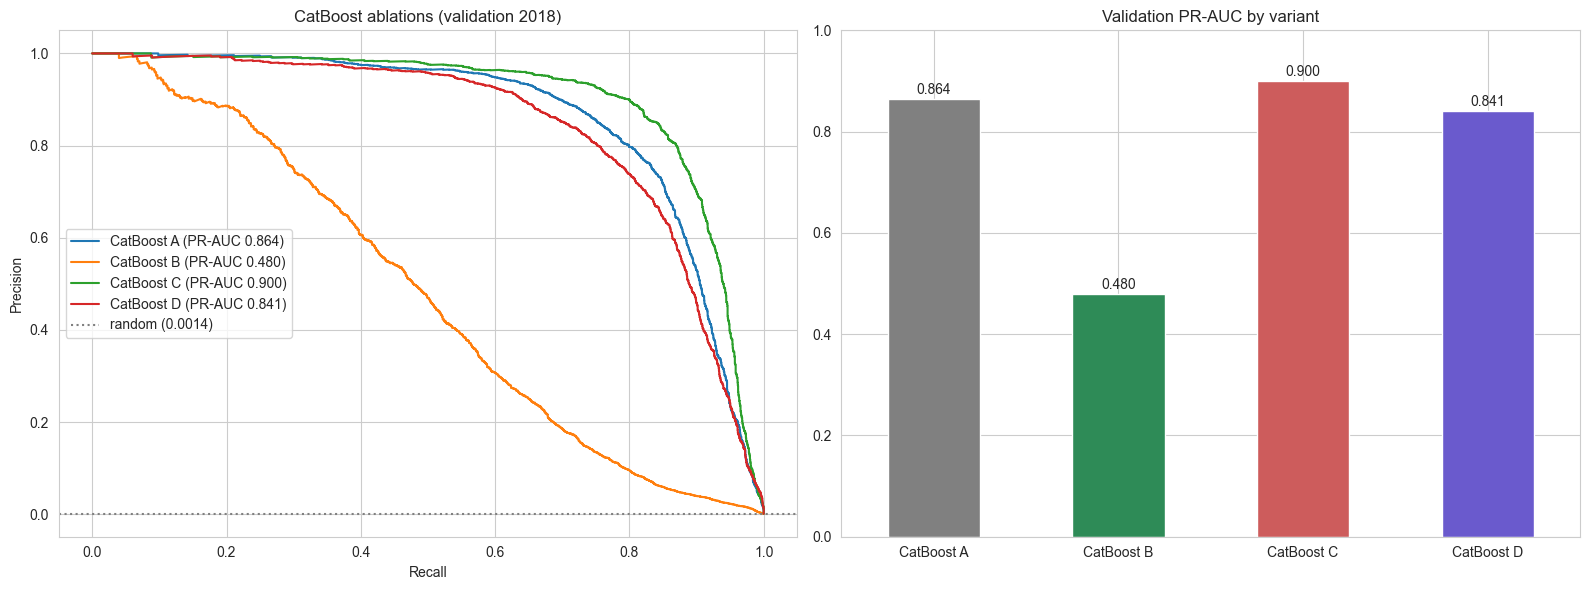

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pr_curves(y_val, val_scores, ax=axes[0], title="CatBoost ablations (validation 2018)")
cb_ablation["pr_auc"].plot(kind="bar", ax=axes[1], color=["grey", "seagreen", "indianred", "slateblue"], rot=0)
axes[1].set(title="Validation PR-AUC by variant", ylim=(0, 1))
for i, v in enumerate(cb_ablation["pr_auc"]):
    axes[1].text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

## 4. Performance by segment

PR-AUC **within** each segment shows whether a model can rank transactions inside a segment, rather than just flag the segment. Recall and precision use each model's own validation threshold (max F1, chosen on all of 2018).

In [6]:
def by_segment(scores: dict, res: dict) -> pd.DataFrame:
    rows = []
    for name, p in scores.items():
        thr = res[name]["threshold"]
        for s in SEGMENTS:
            idx = segment == s
            y, ps = y_val[idx], p[idx]
            flagged = ps >= thr
            tp = int((flagged & (y == 1)).sum())
            rows.append({"model": name, "segment": s, "frauds": int(y.sum()), "base_rate": y.mean(),
                         "pr_auc_within": average_precision_score(y, ps) if y.sum() else np.nan,
                         "alerts@thr": int(flagged.sum()),
                         "recall@thr": tp / max(int(y.sum()), 1),
                         "precision@thr": tp / max(int(flagged.sum()), 1)})
    return pd.DataFrame(rows).set_index(["model", "segment"]).round(4)

seg_cb = by_segment({k: val_scores[k] for k in ["CatBoost A", "CatBoost B"]}, results)
seg_cb

frauds  base_rate  pr_auc_within  \
model      segment                                                    
CatBoost A in-store domestic           23     0.0000         0.1310   
           in-store international    2340     0.1929         0.9799   
           online                     128     0.0006         0.8405   
CatBoost B in-store domestic           23     0.0000         0.1123   
           in-store international    2340     0.1929         0.8651   
           online                     128     0.0006         0.8363   

                                   alerts@thr  recall@thr  precision@thr  
model      segment                                                        
CatBoost A in-store domestic              140      0.4783         0.0786  
           in-store international        1872      0.7821         0.9776  
           online                         369      0.8672         0.3008  
CatBoost B in-store domestic              413      0.4783         0.0266  
           in-store international        1060      0.4380         0.9670  
           online                         673      0.8828         0.1679

## 5. All four models on variant B (no geography)

Same frozen recipes as notebooks 04–06, on B's 28 features: logistic regression, Random Forest (500 trees), CatBoost (from above), FT-Transformer (3 seeds, cosine lr + EMA, 20 epochs; ≈ 75 min, checkpointed every epoch).

In [7]:
a_metrics = pd.concat([
    pd.read_csv(REPORTS_DIR / "val_metrics_traditional.csv", index_col=0).loc[["LogReg (tuned)", "RandomForest (tuned)"]],
    pd.read_csv(REPORTS_DIR / "val_metrics_catboost.csv", index_col=0).loc[["CatBoost (tuned)"]],
    pd.read_csv(REPORTS_DIR / "val_metrics_ft_transformer.csv", index_col=0).loc[["FT-Transformer (tuned)"]],
])
a_metrics.index = [f"{n} A" for n in fm.MODEL_NAMES]

b_results, b_scores = {"CatBoost B": results["CatBoost B"]}, {"CatBoost B": val_scores["CatBoost B"]}
for name in ["LogReg", "RandomForest", "FT-Transformer"]:
    kw = dict(ckpt_dir=CKPT_DIR, tag="stable_B", val=val) if name == "FT-Transformer" else {}
    key = f"{name} B"
    b_scores[key] = fm.score(get(name, "B", **kw), val)
    b_results[key] = evaluate(y_val, b_scores[key])
    log(f"{key}: val PR-AUC {b_results[key]['pr_auc']:.4f}")
order = [f"{n} B" for n in fm.MODEL_NAMES]
b_scores = {k: b_scores[k] for k in order}
b_metrics = compare(b_results).loc[order]

ab = pd.DataFrame({"PR-AUC A": a_metrics["pr_auc"].to_numpy(), "PR-AUC B": b_metrics["pr_auc"].to_numpy(),
                   "recall@P0.5 A": a_metrics["recall@precision0.5"].to_numpy(),
                   "recall@P0.5 B": b_metrics["recall@precision0.5"].to_numpy()}, index=fm.MODEL_NAMES)
ab["PR-AUC drop"] = ab["PR-AUC A"] - ab["PR-AUC B"]
display(ab.round(4))
b_metrics

2026-11-20 20:45:02  LogReg B: fitted in 35s


2026-11-20 20:45:05  LogReg B: val PR-AUC 0.0196


2026-11-20 20:49:54  RandomForest B: fitted in 288s


2026-11-20 20:50:00  RandomForest B: val PR-AUC 0.4827


  epoch 1 | train_loss 0.0471 | secs 53.1488 | val_pr_auc 0.0582


  epoch 2 | train_loss 0.0105 | secs 53.2045 | val_pr_auc 0.0835


... (58 outputs left out)

2026-11-20 21:59:06  FT-Transformer B: fitted in 4146s


2026-11-20 21:59:57  FT-Transformer B: val PR-AUC 0.4237


,PR-AUC A,PR-AUC B,recall@P0.5 A,recall@P0.5 B,PR-AUC drop
LogReg,0.1521,0.0196,0.0024,0.0000,0.1325
RandomForest,0.7155,0.4827,0.8888,0.5608,0.2328
CatBoost,0.8636,0.4802,0.9049,0.4789,0.3834
FT-Transformer,0.5328,0.4237,0.5243,0.4018,0.1091


,pr_auc,roc_auc,recall@precision0.5,precision@top0.1%,recall@top0.1%,threshold,precision@threshold,recall@threshold,alerts@threshold
LogReg B,0.0196,0.8399,0.0000,0.0407,0.0281,0.9639,0.0380,0.0939,6156.0
RandomForest B,0.4827,0.9979,0.5608,0.5767,0.3986,0.5100,0.4995,0.5648,2817.0
CatBoost B,0.4802,0.9862,0.4789,0.5941,0.4107,0.3251,0.5354,0.4613,2146.0
FT-Transformer B,0.4237,0.9794,0.4018,0.5447,0.3766,0.5454,0.5395,0.3838,1772.0


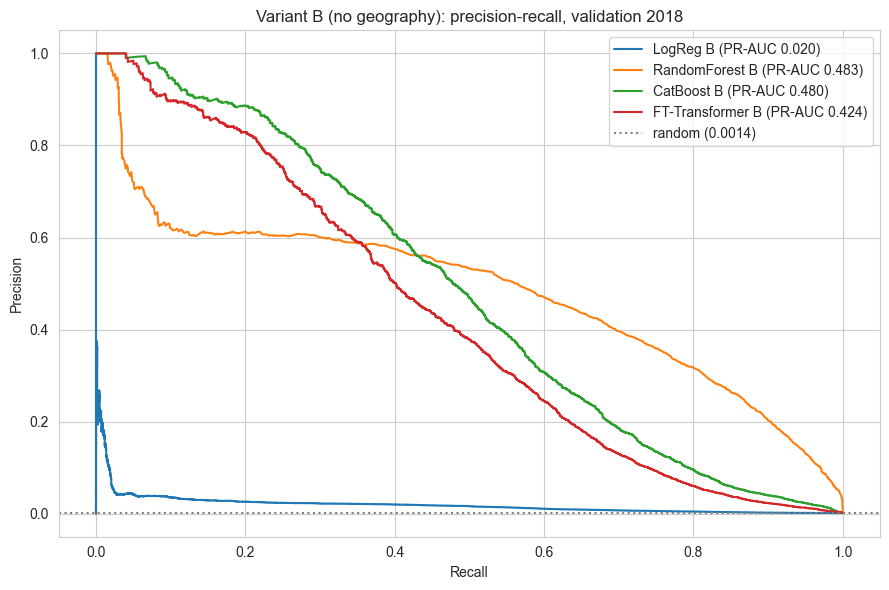

frauds  base_rate  pr_auc_within  \
model            segment                                                    
LogReg B         in-store domestic           23     0.0000         0.0048   
                 in-store international    2340     0.1929         0.4527   
                 online                     128     0.0006         0.0871   
RandomForest B   in-store domestic           23     0.0000         0.0243   
                 in-store international    2340     0.1929         0.9057   
                 online                     128     0.0006         0.7245   
CatBoost B       in-store domestic           23     0.0000         0.1123   
                 in-store international    2340     0.1929         0.8651   
                 online                     128     0.0006         0.8363   
FT-Transformer B in-store domestic           23     0.0000         0.1171   
                 in-store international    2340     0.1929         0.8222   
                 online                     128     0.0006         0.8399   

                                         alerts@thr  recall@thr  precision@thr  
model            segment                                                        
LogReg B         in-store domestic             1160      0.3043         0.0060  
                 in-store international         212      0.0568         0.6274  
                 online                        4784      0.7344         0.0196  
RandomForest B   in-store domestic              326      0.2609         0.0184  
                 in-store international        1406      0.5513         0.9175  
                 online                        1085      0.8672         0.1023  
CatBoost B       in-store domestic              413      0.4783         0.0266  
                 in-store international        1060      0.4380         0.9670  
                 online                         673      0.8828         0.1679  
FT-Transformer B in-store domestic              470      0.4783         0.0234  
                 in-store international         878      0.3564         0.9499  
                 online                         424      0.8672         0.2618

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_pr_curves(y_val, b_scores, ax=ax, title="Variant B (no geography): precision-recall, validation 2018")
plt.tight_layout(); plt.show()

seg_all_b = by_segment(b_scores, b_results)
seg_all_b

## Findings

**Geography is most of the signal.** 94% of 2018 fraud is in-store at foreign merchants (19% fraud rate there, vs 0.002% in-store domestic). Removing the geographic features drops CatBoost from **0.864 to 0.480** val PR-AUC. With `merchant_state` added (variant C) it rises to **0.900**. On this synthetic data, "where is the merchant" is the strongest single fact about a transaction.

| CatBoost variant | Val PR-AUC | Recall @ precision 0.5 |
|---|---|---|
| A: selected | 0.864 | 0.905 |
| **B: no geography** | **0.480** | **0.479** |
| C: + `merchant_state` | 0.900 | 0.940 |
| D: + user snapshots | 0.841 | 0.889 |

**Refitting A with `src/final_models.py` reproduces notebook 05 exactly** (max score difference 3e-8), so B, C and D differ from A only in their features.

**`zip_freq` really was a proxy.** On its own it separates international from domestic in-store transactions with AUC 0.999. With it, a probe classifier recovers `is_international` almost perfectly (PR-AUC 0.989). **Without it, B still carries some geography:** the probe reaches ROC-AUC 0.967 and PR-AUC 0.53 (base rate 0.8%), mainly through `merchant_city_freq` (0.73 alone), `is_new_merchant_for_card` and `merchant_freq`. Rare cities and merchants are often foreign. That is partly a real-world pattern, so these features stay. **B is "no explicit geography", not "no geography": its 0.48 is, if anything, still a little flattering.**

**User snapshots don't help (0.841 vs 0.864).** They stay excluded: no benefit, and a leakage risk.

**What B loses, by segment (CatBoost):**
- **Online fraud is unaffected** (within-segment PR-AUC 0.84 in both A and B; recall 0.87–0.88). Online transactions have no merchant location, so geography never helped there.
- **International in-store** is still ranked well *within* the segment (0.87 vs 0.98). The model can still tell which foreign transactions are fraud. What it loses is the ability to pick out the segment itself: recall at the threshold falls from 0.78 to 0.44.
- **In-store domestic fraud is essentially undetectable** for every model (23 frauds in 1.5M transactions, within-segment PR-AUC ≈ 0.1).

**Without geography the model ranking changes:**

| Model | Val PR-AUC A | Val PR-AUC B | Drop |
|---|---|---|---|
| Logistic regression | 0.152 | 0.020 | 0.133 |
| Random Forest | 0.716 | **0.483** | 0.233 |
| CatBoost | 0.864 | **0.480** | 0.383 |
| FT-Transformer | 0.533 | 0.424 | 0.109 |

- **CatBoost's lead disappears.** Random Forest and CatBoost are tied on B (0.483 vs 0.480). Much of CatBoost's advantage in A came from exploiting the geographic features better. CatBoost is still slightly more precise at its threshold (0.54 vs 0.50, with fewer alerts), and the Random Forest catches more international frauds.
- **The FT-Transformer loses the least** (0.11) and stays close behind (0.424). It relied less on geography to begin with.
- **Logistic regression collapses to 0.020.** It was essentially a geography detector: linear terms can't recombine the remaining features into "foreign merchant".
- These B models use A's hyperparameters, which were tuned with geography available. Re-tuning on B might narrow or widen the gaps a little. It was deliberately not done, so that the variants differ only in their features.

**For the test evaluation (notebook 08):** B is the headline result, with A next to it. Test intervals will show whether Random Forest and CatBoost on B can be told apart at all.


## 6. Save

In [9]:
cb_ablation.to_csv(REPORTS_DIR / "val_metrics_ablation_catboost.csv")
b_metrics.to_csv(REPORTS_DIR / "val_metrics_variant_B.csv")
pd.concat([seg_cb, seg_all_b.drop("CatBoost B", level="model")]).to_csv(REPORTS_DIR / "val_metrics_by_segment.csv")
probe_res.to_csv(REPORTS_DIR / "geo_leakage_probe.csv")
(REPORTS_DIR / "feature_variants.json").write_text(json.dumps(
    {"variants": VARIANTS, "headline": "B",
     "val_thresholds": {**{k: float(a_metrics.loc[k, "threshold"]) for k in a_metrics.index},
                        **{k: float(v["threshold"]) for k, v in b_results.items()}}}, indent=2))
pd.DataFrame({**val_scores, **b_scores}).astype("float32").to_parquet(CACHE / "val_scores_ablation.parquet")
print("Saved ablation metrics, segment table, probe, variants and thresholds.")

Saved ablation metrics, segment table, probe, variants and thresholds.
